# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Бубельник Юрій'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ'      # напр. 'КН-31'
ВАРІАНТ = 2     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 2 · Бубельник Юрій, ШІ, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            4    2        5       2   1271
Столярний цех, год         6    5        4       2    702
Фарбувальний цех, год      5    2        0       3    915
Такелаж, компл.            2    1        5       0   1388
Ділянка добудови, год      5    5        6       2    804

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     40   66       24      34

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Столярний цех, год
  ціна:   16.7 за одиницю
  обсяг:  до 204 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: x1 - Sting x2 - Ray x3 - Breaker x4 - Marlin

Цільова функція: maxZ = 40x1 + 66x2 + 24x3 + 34x4

Обмеження:

4x1 + 2x2 + 5x3 + 2x4 <= 1271 - склопластик
6x1 + 5x2 + 4x3 + 2x4 <= 702 - столярний цех
5x1 + 2x2 + 0x3 + 3x4 <= 915 - фарбувальний цех
2x1 + x2 + 5x3 + 0x4 <= 1388 - такелаж
5x1 + 5x2 + 6x3 + 2x4 <= 804 - ділянка добудови

Невід'ємність:
x1, x2, x3, x4 >= 0

### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**
Запас ресурсу є параметром, тому що його кількість наперед задана і підприємство не обирає її під час оптимізації. Модель визначає лише кількість яхт кожного типу, яку потрібно виготовити в межах наявних ресурсів.

Якби підприємство могло докуповувати ресурс у будь-якій кількості, потрібно було б додати нову змінну рішення, наприклад y — кількість додатково придбаного ресурсу. Тоді його вартість враховувалась би у цільовій функції

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [0, 25, 0, 288]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 11442         # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [0, 25, 0, 288] | прибуток 11442


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds

# Прибуток
profit = np.array([40, 66, 24, 34])

# Витрати ресурсів
A = np.array([
    [4, 2, 5, 2],
    [6, 5, 4, 2],
    [5, 2, 0, 3],
    [2, 1, 5, 0],
    [5, 5, 6, 2]
])

# Запаси ресурсів
b = np.array([1271, 702, 915, 1388, 804])

# Обмеження A*x <= b
constraints = LinearConstraint(A, 0, b)

# x >= 0
bounds = Bounds(0, np.inf)

# Розв'язання
r = milp(
    c=-profit,                 # мінус, бо milp мінімізує
    integrality=np.ones(4),    # усі 4 змінні — цілі
    bounds=bounds,
    constraints=constraints
)

план = r.x.astype(int)
прибуток = int(round(-r.fun))

print("Оптимальний план:", план)
print("Максимальний прибуток:", прибуток)

Оптимальний план: [  0  25   0 288]
Максимальний прибуток: 11442


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс           | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
| ---------------- | ---------------: | -----------: | ------------: | -------------------: | ------------------: |
| Склопластик      |      626.7272727 |            0 |          1271 |                1E+30 |         644.2727273 |
| Столярний цех    |              702 |  11.81818182 |           702 |                  102 |                  92 |
| Фарбувальний цех |              915 |  3.454545455 |           915 |                  138 |               634.2 |
| Такелаж          |      25.09090909 |            0 |          1388 |                1E+30 |         1362.909091 |
| Ділянка добудови |              702 |            0 |           804 |                1E+30 |                 102 |


**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**
У дефіциті знаходяться столярний і фарбувальний цехи, оскільки їх ресурси використані повністю: 702 із 702 та 915 із 915, а їх тіньові ціни більші за 0. Склопластик, такелаж і ділянка добудови мають залишок ресурсу, тому їх тіньова ціна дорівнює 0.

### Завдання 4.2 — блок «Змінні»

| Виріб   | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
| ------- | ---------------: | ---------------: | ------------------: | -------------------: | ------------------: |
| Sting   |                0 |     -48.18181818 |                  40 |          48.18181818 |               1E+30 |
| Ray     |      25.09090909 |                0 |                  66 |                   19 |         21.33333333 |
| Breaker |                0 |     -23.27272727 |                  24 |          23.27272727 |               1E+30 |
| Marlin  |      288.2727273 |                0 |                  34 |                   32 |                 7.6 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Не виробляються Sting і Breaker. Для Sting прибуток з одиниці має зрости на 48.1818, тобто з 40 до 88.1818, щоб він міг увійти в оптимальний план. Для Breaker прибуток має зрости на 23.2727, тобто з 24 до 47.2727. Ці числа взяті зі стовпця «Зменшена вартість» звіту про стійкість за модулем.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# ВАШ КОД
import numpy as np
from scipy.optimize import linprog

c = np.array([40, 66, 24, 34])

A = np.array([
    [4, 2, 5, 2],
    [6, 5, 4, 2],
    [5, 2, 0, 3],
    [2, 1, 5, 0],
    [5, 5, 6, 2]
])

b = np.array([1271, 702, 915, 1388, 804])

# Початковий розв'язок
r1 = linprog(
    -c,
    A_ub=A,
    b_ub=b,
    bounds=[(0, None)] * 4,
    method="highs"
)

profit1 = -r1.fun

# Збільшуємо запас столярного цеху на 1 годину
b_new = b.copy()
b_new[1] += 1

r2 = linprog(
    -c,
    A_ub=A,
    b_ub=b_new,
    bounds=[(0, None)] * 4,
    method="highs"
)

profit2 = -r2.fun

increase = profit2 - profit1

print("Початковий прибуток:", profit1)
print("Новий прибуток:", profit2)
print("Приріст прибутку:", increase)

Початковий прибуток: 11457.272727272726
Новий прибуток: 11469.09090909091
Приріст прибутку: 11.818181818183803


**Відповідь 5.1:** *(приріст прибутку = ..., тіньова ціна зі звіту = ..., збігаються?)*
Приріст прибутку = 11.8182, тіньова ціна зі звіту = 11.8182. Значення збігаються, тому тіньова ціна правильно показує, на скільки збільшиться максимальний прибуток при збільшенні запасу столярного цеху на 1 годину в межах допустимого інтервалу.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Тіньова ціна: 11.8181818
Межа діапазону: 804
Допустиме збільшення: 102


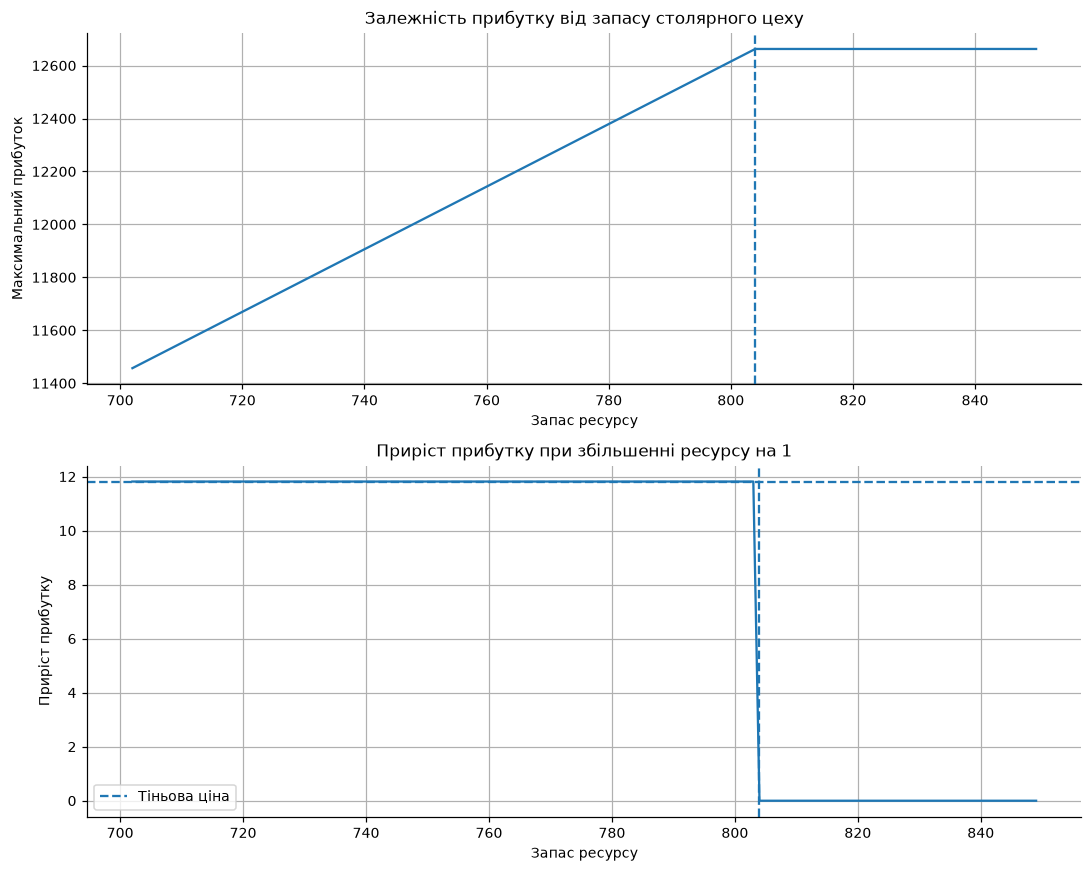

In [8]:
# ВАШ КОД
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# Прибуток
c = np.array([40, 66, 24, 34])

# Витрати ресурсів
A = np.array([
    [4, 2, 5, 2],
    [6, 5, 4, 2],
    [5, 2, 0, 3],
    [2, 1, 5, 0],
    [5, 5, 6, 2]
])

# Початкові запаси
b = np.array([1271, 702, 915, 1388, 804])

# Столярний цех — ресурс з найбільшою тіньовою ціною
resource_index = 1
base_resource = 702

# Тіньова ціна зі звіту
shadow_price = 11.8181818

# Перевіряємо запас від 702 до 850 з кроком 1
resource_values = np.arange(base_resource, 851)
profits = []

for value in resource_values:
    b_new = b.copy()
    b_new[resource_index] = value

    r = linprog(
        -c,
        A_ub=A,
        b_ub=b_new,
        bounds=[(0, None)] * 4,
        method="highs"
    )

    profits.append(-r.fun)

profits = np.array(profits)

# Приріст прибутку при додаванні 1 одиниці ресурсу
increments = np.diff(profits)

# Шукаємо точку, де приріст перестає дорівнювати тіньовій ціні
break_indices = np.where(
    np.abs(increments - shadow_price) > 1e-5
)[0]

if len(break_indices) > 0:
    boundary = resource_values[break_indices[0]]
else:
    boundary = resource_values[-1]

print("Тіньова ціна:", shadow_price)
print("Межа діапазону:", boundary)
print("Допустиме збільшення:", boundary - base_resource)

# Графіки
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Графік прибутку
axes[0].plot(resource_values, profits)
axes[0].axvline(boundary, linestyle="--")
axes[0].set_title("Залежність прибутку від запасу столярного цеху")
axes[0].set_xlabel("Запас ресурсу")
axes[0].set_ylabel("Максимальний прибуток")
axes[0].grid()

# Графік приросту прибутку
axes[1].plot(resource_values[:-1], increments)
axes[1].axhline(
    shadow_price,
    linestyle="--",
    label="Тіньова ціна"
)
axes[1].axvline(boundary, linestyle="--")
axes[1].set_title("Приріст прибутку при збільшенні ресурсу на 1")
axes[1].set_xlabel("Запас ресурсу")
axes[1].set_ylabel("Приріст прибутку")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*

Межа діапазону становить 804 год., тобто допустиме збільшення запасу столярного цеху від базового значення 702 становить 102 год. До цієї межі приріст прибутку залишається сталим і дорівнює тіньовій ціні 11.8182. Після досягнення межі залежність змінюється, тому початкова тіньова ціна більше не діє.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною. Не брати, оскільки ціна постачальника 16 перевищує тіньову ціну ресурсу 11,82.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно. 0 годин. Навіть перша додаткова година коштує дорожче, ніж додатковий прибуток, який вона
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом. Додатковий прибуток від закупівлі становитиме 0, оскільки оптимальне рішення — нічого не купувати.

In [9]:
# ВАШ КОД
shadow_price = 11.8181818
supplier_price = 16
supplier_limit = 204

profit_per_unit = shadow_price - supplier_price

if profit_per_unit > 0:
    print("Закупівля вигідна")
else:
    print("Закупівля невигідна")

print("Тіньова ціна:", shadow_price)
print("Ціна постачальника:", supplier_price)
print("Результат з 1 додаткової години:", profit_per_unit)
print("Оптимально купити: 0 годин")
print("Додатковий прибуток: 0")

Закупівля невигідна
Тіньова ціна: 11.8181818
Ціна постачальника: 16
Результат з 1 додаткової години: -4.1818182
Оптимально купити: 0 годин
Додатковий прибуток: 0


**Відповідь 6.1:**

* Брати чи ні і чому: Брати чи ні і чому: не брати, оскільки ціна постачальника 16 за одиницю перевищує тіньову ціну ресурсу 11.8182. Одна додаткова одиниця ресурсу приносить менше прибутку, ніж коштує.
* Скільки одиниць має сенс купити і чому не більше: 0 одиниць. Уже перша додаткова одиниця є невигідною, тому купувати більший обсяг також немає сенсу.
* Очікуваний виграш: 0
* Перевірка прямим розв'язанням дала: оптимальний обсяг закупівлі — 0 одиниць, тому прибуток не збільшився і залишився 11457.27.


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
# ВАШ КОД
ненульових = None
звязних = None
import numpy as np

план = np.array([0, 25.09090909, 0, 288.27272727])

використано = np.array([
    626.7272727,
    702,
    915,
    25.09090909,
    702
])

запаси = np.array([1271, 702, 915, 1388, 804])

# Кількість виробів, які реально виробляються
ненульових = np.sum(план > 1e-6)

# Кількість ресурсів, використаних повністю
звязних = np.sum(np.isclose(використано, запаси))

print("Ненульових виробів:", ненульових)
print("Зв'язних обмежень:", звязних)

Ненульових виробів: 2
Зв'язних обмежень: 2


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** *(чи збіглися числа; що означала б розбіжність на практиці)* Кількість виробів з ненульовим випуском дорівнює 2, кількість зв’язних обмежень також дорівнює 2. Отже, у даному оптимальному розв’язку ці величини збігаються.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
# ВАШ КОД
import numpy as np
from scipy.optimize import linprog

# Прибуток
c = np.array([40, 66, 24, 34])

# Витрати ресурсів
A = np.array([
    [4, 2, 5, 2],
    [6, 5, 4, 2],
    [5, 2, 0, 3],
    [2, 1, 5, 0],
    [5, 5, 6, 2]
])

# Запаси
b = np.array([1271, 702, 915, 1388, 804])

# 1. Звичайний LP без цілочисельності
r_lp = linprog(
    -c,
    A_ub=A,
    b_ub=b,
    bounds=[(0, None)] * 4,
    method="highs"
)

план_lp = r_lp.x
прибуток_lp = -r_lp.fun

# 2. Просте округлення
план_окр = np.rint(план_lp).astype(int)
прибуток_окр = c @ план_окр
допустимий_окр = np.all(A @ план_окр <= b)

# 3. Справжній цілочисельний оптимум
r_int = linprog(
    -c,
    A_ub=A,
    b_ub=b,
    bounds=[(0, None)] * 4,
    integrality=np.ones(4),
    method="highs"
)

план_int = np.rint(r_int.x).astype(int)
прибуток_int = -r_int.fun

print("Без цілочисельності:")
print("План:", план_lp)
print("Прибуток:", прибуток_lp)

print("\nОкруглений:")
print("План:", план_окр)
print("Прибуток:", прибуток_окр)
print("Допустимий:", допустимий_окр)

print("\nЦілочисельний оптимум:")
print("План:", план_int)
print("Прибуток:", прибуток_int)

Без цілочисельності:
План: [  0.          25.09090909   0.         288.27272727]
Прибуток: 11457.272727272726

Округлений:
План: [  0  25   0 288]
Прибуток: 11442
Допустимий: True

Цілочисельний оптимум:
План: [  0  25   0 288]
Прибуток: 11442.0


**Відповідь 8.1:**

| Варіант                   | План                      | Прибуток | Допустимий?                             |
| ------------------------- | ------------------------- | -------: | --------------------------------------- |
| без умови цілочисельності | [0; 25.0909; 0; 288.2727] | 11457.27 | так для LP, але план нереальний для яхт |
| округлений                | [0; 25; 0; 288]           |    11442 | так                                     |
| цілочисельний оптимум     | [0; 25; 0; 288]           |    11442 | так                                     |


**Висновок:** *(чи можна округлювати і чому)* У цьому конкретному випадку округлення дало той самий план, що й справжній цілочисельний оптимум, тому округлення спрацювало. Але загалом просто округляти не можна, бо округлений план може порушити ресурсні обмеження або дати менший прибуток, ніж справжній цілочисельний оптимум.


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# ВАШ КОД — впишіть свої дані
import numpy as np
import pandas as pd

постачальники = ['Броди', 'Умань', 'Біла Церква']

споживачі = [
    'Южне',
    'Рівне',
    'Івано-Франківськ',
    'Буча'
]

D = np.array([
    [650, 109, 166, 430],
    [315, 424, 496, 230],
    [430, 339, 524, 104]
])

запас = [20, 30, 25]
попит = [15, 20, 25, 15]

assert len(постачальники) == 3 and len(споживачі) == 4
assert D.shape == (3, 4)
assert sum(запас) == sum(попит)

pd.DataFrame(D, index=постачальники, columns=споживачі)

,Южне,Рівне,Івано-Франківськ,Буча
Броди,650,109,166,430
Умань,315,424,496,230
Біла Церква,430,339,524,104


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# ВАШ КОД — розв'язок 1
import numpy as np
import pandas as pd
from scipy.optimize import linprog

постачальники = ['Броди', 'Умань', 'Біла Церква']
споживачі = ['Южне', 'Рівне', 'Івано-Франківськ', 'Буча']

D = np.array([
    [650, 109, 166, 430],
    [315, 424, 496, 230],
    [430, 339, 524, 104]
])

запас = np.array([20, 30, 25])
попит = np.array([15, 20, 25, 15])

n = len(постачальники)
m = len(споживачі)

# Цільова функція
c = D.flatten()

A_eq = []
b_eq = []

# Обмеження запасу постачальників
for i in range(n):
    row = np.zeros(n * m)

    for j in range(m):
        row[i * m + j] = 1

    A_eq.append(row)
    b_eq.append(запас[i])

# Обмеження попиту споживачів
for j in range(m):
    row = np.zeros(n * m)

    for i in range(n):
        row[i * m + j] = 1

    A_eq.append(row)
    b_eq.append(попит[j])

A_eq = np.array(A_eq)
b_eq = np.array(b_eq)

r = linprog(
    c,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=(0, None),
    method='highs'
)

план1 = r.x.reshape(n, m)

print("Оптимальний план перевезень:")
print(pd.DataFrame(
    план1,
    index=постачальники,
    columns=споживачі
))

print("\nСумарна вартість:", r.fun)

print("\nТіньові ціни:")

shadow = r.eqlin.marginals

for i in range(n):
    print(
        "Запас", постачальники[i],
        "=", shadow[i]
    )

for j in range(m):
    print(
        "Попит", споживачі[j],
        "=", shadow[n + j]
    )

Оптимальний план перевезень:
             Южне  Рівне  Івано-Франківськ  Буча
Броди         0.0    0.0              20.0   0.0
Умань        15.0   10.0               5.0   0.0
Біла Церква   0.0   10.0               0.0  15.0

Сумарна вартість: 19715.0

Тіньові ціни:
Запас Броди = 94.0
Запас Умань = 424.0
Запас Біла Церква = 339.0
Попит Южне = -109.0
Попит Рівне = -0.0
Попит Івано-Франківськ = 72.0
Попит Буча = -235.0


In [15]:
# ВАШ КОД — розв'язок 2
import numpy as np
import pandas as pd
from scipy.optimize import linprog

постачальники = ['Броди', 'Умань', 'Біла Церква']
споживачі = ['Южне', 'Рівне', 'Івано-Франківськ', 'Буча']

D = np.array([
    [650, 109, 166, 430],
    [315, 424, 496, 230],
    [430, 339, 524, 104]
])

запас = np.array([20, 30, 25])
попит = np.array([15, 20, 25, 15])

n = len(постачальники)
m = len(споживачі)

# Цільова функція
c = D.flatten()

A_eq = []
b_eq = []

# Обмеження запасу постачальників
for i in range(n):
    row = np.zeros(n * m)

    for j in range(m):
        row[i * m + j] = 1

    A_eq.append(row)
    b_eq.append(запас[i])

# Обмеження попиту споживачів
for j in range(m):
    row = np.zeros(n * m)

    for i in range(n):
        row[i * m + j] = 1

    A_eq.append(row)
    b_eq.append(попит[j])

A_eq = np.array(A_eq)
b_eq = np.array(b_eq)

r = linprog(
    c,
    A_eq=A_eq,
    b_eq=b_eq,
    bounds=(0, None),
    method='highs'
)

план1 = r.x.reshape(n, m)

print("Оптимальний план перевезень:")
print(pd.DataFrame(
    план1,
    index=постачальники,
    columns=споживачі
))

print("\nСумарна вартість:", r.fun)

print("\nТіньові ціни:")

shadow = r.eqlin.marginals

for i in range(n):
    print(
        "Запас", постачальники[i],
        "=", shadow[i]
    )

for j in range(m):
    print(
        "Попит", споживачі[j],
        "=", shadow[n + j]
    )

Оптимальний план перевезень:
             Южне  Рівне  Івано-Франківськ  Буча
Броди         0.0    0.0              20.0   0.0
Умань        15.0   10.0               5.0   0.0
Біла Церква   0.0   10.0               0.0  15.0

Сумарна вартість: 19715.0

Тіньові ціни:
Запас Броди = 94.0
Запас Умань = 424.0
Запас Біла Церква = 339.0
Попит Южне = -109.0
Попит Рівне = -0.0
Попит Івано-Франківськ = 72.0
Попит Буча = -235.0


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
# ВАШ КОД — порівняння
import numpy as np
from scipy.optimize import linprog
import pulp

# Дані
D = np.array([
    [650, 109, 166, 430],
    [315, 424, 496, 230],
    [430, 339, 524, 104]
])

запас = np.array([20, 30, 25])
попит = np.array([15, 20, 25, 15])

n = 3
m = 4

# -------------------------
# 1. SciPy
# -------------------------

c = D.flatten()

A_eq = []
b_eq = []

for i in range(n):
    row = np.zeros(n * m)
    for j in range(m):
        row[i * m + j] = 1
    A_eq.append(row)
    b_eq.append(запас[i])

for j in range(m):
    row = np.zeros(n * m)
    for i in range(n):
        row[i * m + j] = 1
    A_eq.append(row)
    b_eq.append(попит[j])

r = linprog(
    c,
    A_eq=np.array(A_eq),
    b_eq=np.array(b_eq),
    bounds=(0, None),
    method="highs"
)

shadow1 = r.eqlin.marginals

# -------------------------
# 2. PuLP
# -------------------------

model = pulp.LpProblem("Transport", pulp.LpMinimize)

x = {
    (i, j): pulp.LpVariable(f"x_{i}_{j}", lowBound=0)
    for i in range(n)
    for j in range(m)
}

model += pulp.lpSum(
    D[i, j] * x[i, j]
    for i in range(n)
    for j in range(m)
)

for i in range(n):
    model += (
        pulp.lpSum(x[i, j] for j in range(m)) == запас[i],
        f"supply_{i}"
    )

for j in range(m):
    model += (
        pulp.lpSum(x[i, j] for i in range(n)) == попит[j],
        f"demand_{j}"
    )

model.solve(pulp.PULP_CBC_CMD(msg=False))

shadow2 = np.array(
    [model.constraints[f"supply_{i}"].pi for i in range(n)] +
    [model.constraints[f"demand_{j}"].pi for j in range(m)]
)

# -------------------------
# Порівняння
# -------------------------

print("SciPy:", shadow1)
print("PuLP: ", shadow2)

difference = shadow1 - shadow2

print("\nРізниця:", difference)

print("\nРізниця для постачальників:")
print(difference[:n])

print("\nРізниця для споживачів:")
print(difference[n:])

print("\nВартість SciPy:", r.fun)
print("Вартість PuLP:", pulp.value(model.objective))

SciPy: [  94.  424.  339. -109.   -0.   72. -235.]
PuLP:  [ -15.  315.  230.    0.  109.  181. -126.]

Різниця: [ 109.  109.  109. -109. -109. -109. -109.]

Різниця для постачальників:
[109. 109. 109.]

Різниця для споживачів:
[-109. -109. -109. -109.]

Вартість SciPy: 19715.0
Вартість PuLP: 19715.0


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: Вартість у двох розв’язувачів: 19715, однакова.
* Тіньові ціни збіглися чи ні: можуть не збігатися, але обидва набори є коректними.
* Яку закономірність ви побачили в різниці: тіньові ціни постачальників відрізняються на одну й ту саму константу, а тіньові ціни споживачів — на цю саму константу з протилежним знаком. Це виникає через залежність одного з обмежень у збалансованій транспортній задачі.
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: не слід порівнювати окремі абсолютні тіньові ціни з різних solver-ів напряму. Важливо, що вони описують ту саму економічну залежність і приводять до однакового оптимального плану та вартості.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
# ВАШ КОД
import numpy as np

# Оптимальний план з етапу 10
план = план1

# Скільки перевезень ненульові
ненульових_транспорт = np.sum(план1 > 1e-9)
звязних_транспорт = np.sum(np.isclose(r.eqlin.residual, 0))

print("Ненульових перевезень:", ненульових_транспорт)
print("Зв'язних обмежень:", звязних_транспорт)
print("Кількість усіх обмежень:", 3 + 4)

Ненульових перевезень: 6
Зв'язних обмежень: 7
Кількість усіх обмежень: 7


**Відповідь 11.1:**

* Ненульових перевезень: 6 
* Зв'язних обмежень: 7 
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження: усі обмеження запасу та попиту задані як рівності, тому кожен постачальник повинен відправити весь свій запас, а кожен споживач отримати весь свій попит.
* На скільки ненульових перевезень менше і чому саме на стільки: ненульових перевезень на 1 менше — 6 замість 7. Причина в тому, що одне з семи обмежень є залежним від інших, оскільки сумарний запас дорівнює сумарному попиту. Тому незалежних обмежень фактично 3 + 4 - 1 = 6.


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

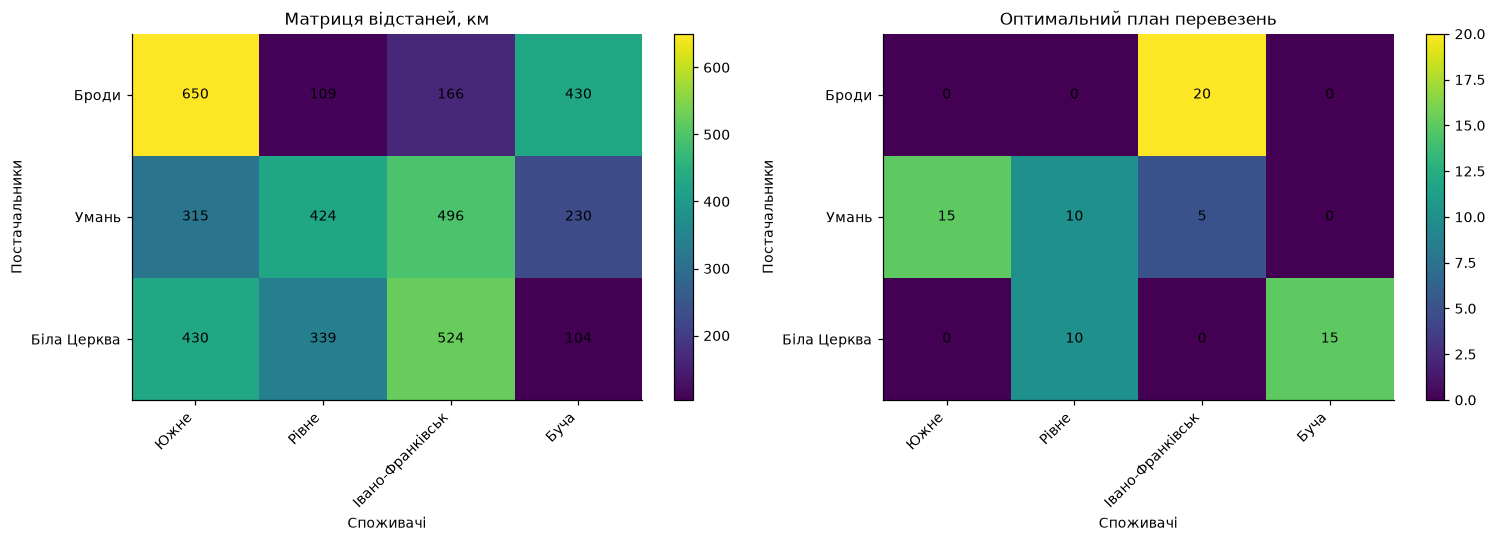

In [18]:
# ВАШ КОД
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Теплова карта відстаней
im1 = axes[0].imshow(D, aspect='auto')

axes[0].set_title('Матриця відстаней, км')
axes[0].set_xlabel('Споживачі')
axes[0].set_ylabel('Постачальники')

axes[0].set_xticks(range(len(споживачі)))
axes[0].set_xticklabels(споживачі, rotation=45, ha='right')

axes[0].set_yticks(range(len(постачальники)))
axes[0].set_yticklabels(постачальники)

# Значення в комірках
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        axes[0].text(
            j, i,
            f'{D[i, j]:.0f}',
            ha='center',
            va='center'
        )

fig.colorbar(im1, ax=axes[0])


# 2. Теплова карта оптимальних перевезень
im2 = axes[1].imshow(план1, aspect='auto')

axes[1].set_title('Оптимальний план перевезень')
axes[1].set_xlabel('Споживачі')
axes[1].set_ylabel('Постачальники')

axes[1].set_xticks(range(len(споживачі)))
axes[1].set_xticklabels(споживачі, rotation=45, ha='right')

axes[1].set_yticks(range(len(постачальники)))
axes[1].set_yticklabels(постачальники)

# Значення в комірках
for i in range(план1.shape[0]):
    for j in range(план1.shape[1]):
        axes[1].text(
            j, i,
            f'{план1[i, j]:.0f}',
            ha='center',
            va='center'
        )

fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

 **Висновок:** *(одне речення про те, що видно на теплових картах)* 

 Оптимальний план використовує лише частину можливих маршрутів, віддаючи перевагу маршрутам, які дозволяють задовольнити весь попит і запас із мінімальними сумарними транспортними витратами.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [19]:
ІНСТРУМЕНТИ_ШІ = 'ChatGPT'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':             'текст, перероблено',
    'етап 2, побудова моделі в Excel':         'ні',
    'етап 3, код на Python':                    'код, перевірено',
    'етапи 4–5, читання та перевірка звіту':   'текст, перероблено',
    'етап 6, рішення про закупівлю':            'текст, перероблено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':           'код, перевірено',
}

ЩО_ПЕРЕВІРЕНО = (
    'Перевірено правильність коефіцієнтів цільової функції та обмежень, '
    'результати Excel і Python, виконання ресурсних обмежень, '
    'цілочисельний оптимум, тіньові ціни та допустимі діапазони, '
    'а також баланс запасу і попиту та результати транспортної задачі.'
)

ПІДТВЕРДЖУЮ = True

In [20]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Бубельник Юрій
інструменти:                               ChatGPT
------------------------------------------------------------------------------
етап 1, формалізація моделі:               текст, перероблено
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     текст, перероблено
етап 6, рішення про закупівлю:             текст, перероблено
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
Перевірено правильність коефіцієнтів цільової функції та обмежень, результати Excel і Python, виконання ресурсних обмежень, цілочисельний оптимум, тіньові ціни та допустимі діапазони, а також баланс запасу і попиту та результати транспортної задачі.


---
# Крок 13. Фінальна самоперевірка

In [21]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
